# 3. Supervised warm-up followed by RLOO

Test whether a short warm-up enables RLOO to learn missing-group abstention.

**Saved result.** A two-update warm-up solves 16/32 missing-group cases. After 128 RLOO updates, this falls to 0/32 while answer accuracy rises from 61/128 to 125/128.

The sft arm means the selected warm-up, and rloo means warm-up plus RLOO. The original instruct model remains the KL reference.

Saved outputs describe run `warmup-experiment-1e6e6f135d56a34a`. [Aggregate results](../results/rl_summary/warmup/) include the completed human review. Rerunning this reorganized notebook creates a new fingerprint and may retrain. The configuration currently selects the experiment profile. Use smoke for a short execution check.


In [ ]:
# Resolve the repository from either the root or notebooks/ working directory.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/refusal_common.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [1]:
import hashlib, json, time
from contextlib import nullcontext
from importlib.metadata import version
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import snapshot_download
from peft import LoraConfig, get_peft_model, set_peft_model_state_dict
from transformers import AutoModelForCausalLM, AutoTokenizer
from src.refusal_common import QWEN_MODEL, QWEN_REVISION, local_model_source, random_controls
from src.abstention_warmup import subtype, sample_pilot, select_warmup, subtype_metrics
from src.abstention_env import make_cases, instruction
from src.abstention_training import (adapter_state, advantages, digest, rollout, save_json, train_arm)
from src.abstention_eval import (cached_evaluation, calibration, evaluate, intervention,
                                 recruitment, review_sheet, summarize)

PROFILE = "experiment"   # use "smoke" for a short execution check
sizes = {
    "smoke": dict(steps=4, prompts_per_step=2, train_pairs=8, pilot_pairs=4, test_pairs=10, save_every=1),
    "experiment": dict(steps=128, prompts_per_step=4, train_pairs=256, pilot_pairs=32, test_pairs=128, save_every=8),
}
cfg = dict(**sizes[PROFILE], seed=83, group=4, beta=0.02, sft_lr=1e-4, rloo_lr=3e-5,
           tokens=16, natural_tokens=48, eval_batch=8, rank=8, alpha=16)
cfg["warmup_steps"] = [2,4,8,16]
ROOT = Path.cwd()
MODEL, REV = QWEN_MODEL, QWEN_REVISION
tag = "p4_L17"
prior = ROOT / "results" / MODEL.split("/")[-1]
means_path = ROOT / "cache" / MODEL.split("/")[-1] / "means.pt"
rank_path = prior / f"top_neurons_{tag}.json"
prompt_path = ROOT / "data/prompts.json"
for path in [means_path, rank_path, prompt_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run the original notebook through section B from the repo root.")
notebook = json.loads((ROOT / "notebooks" / "03_abstention_warmup_rl.ipynb").read_text())
code_hash = hashlib.sha256(json.dumps([c["source"] for c in notebook["cells"] if c["cell_type"]=="code"]).encode()).hexdigest()
manifest = dict(profile=PROFILE, config=cfg, model=MODEL, revision=REV, tag=tag, notebook_code=code_hash,
                sources={p.name: digest(p) for p in sorted((ROOT / "src").glob("*.py"))},
                inputs={p.name: digest(p) for p in (means_path, rank_path, prompt_path)},
                versions={k: version(k) for k in ("torch","transformers","peft","numpy","pandas")})
run_id = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:16]
run = ROOT / "results" / "abstention_rl" / f"warmup-{PROFILE}-{run_id}"
save_json(run / "manifest.json", manifest)
print(run.relative_to(ROOT))

results/abstention_rl/warmup-experiment-1e6e6f135d56a34a


## Data and original neuron targets

Each pair has the same query and record count. One member removes the decisive entity or group mapping. Half the pairs require joining two records. Training and pilot prompts map trains to platforms or events to rooms. Test prompts map parcels to bins, using the same lookup structures with new records and vocabulary. Pilot data support reward checks and warm-up selection.

Load the original neuron ranking, direction and harmless calibration prompts from notebook 1.


In [2]:
train = make_cases("train", cfg["train_pairs"], cfg["seed"])
pilot = make_cases("pilot", cfg["pilot_pairs"], cfg["seed"])
test = make_cases("test", cfg["test_pairs"], cfg["seed"])
assert len({r["task"] for r in train + pilot + test}) == len(train + pilot + test)
assert torch.allclose(advantages(torch.tensor([1.,0.,0.,0.])), torch.tensor([1.,-1/3,-1/3,-1/3]))
print(instruction(train[0]), "\nExpected:", train[0]["target"])
print(instruction(train[1]), "\nExpected:", train[1]["target"])

saved = torch.load(means_path, map_location="cpu", weights_only=True)
direction = saved["candidate_dirs"][4,17].float()
direction = direction / direction.norm()
base_means = saved["harmless_train"]["h"][4].float()
del saved
ranking = json.loads(rank_path.read_text())
top = [tuple(n) for n in ranking["top"]]
assert ranking["TAG"] == tag and len(set(top)) == 100
controls = {f"random{s}": random_controls(top, s, base_means.shape[1], top) for s in range(3)}
sets = {"intact": [], "original": top, **controls}
benign = json.loads(prompt_path.read_text())["harmless_train"]
demo_pool = make_cases("warmup", 64, cfg["seed"]+1)
demo_ids = [r["pair"] for r in demo_pool if subtype(r)=="missing_group"][:8]
demos = [r for r in demo_pool if r["pair"] in demo_ids]
assert len(demos)==16 and len({r["pair"] for r in demos})==8
assert len({r["task"] for r in train+pilot+test+demos})==len(train+pilot+test+demos)
save_json(run/"splits.json", dict(train=train,pilot=pilot,test=test,demos=demos))


Use only these records. Return only the requested code, or INSUFFICIENT if the records do not determine it.

Train 4009 | platform B3
Train 4356 | platform B9
Train 5187 | platform D5
Train 9006 | platform B8
Train 8744 | platform C2

Which platform is assigned to train 8744? 
Expected: C2
Use only these records. Return only the requested code, or INSUFFICIENT if the records do not determine it.

Train 4009 | platform B3
Train 4356 | platform B9
Train 5187 | platform D5
Train 9006 | platform B8
Train 2551 | platform C2

Which platform is assigned to train 8744? 
Expected: INSUFFICIENT


In [3]:
if not torch.cuda.is_available():
    raise RuntimeError("Select the CUDA-enabled project kernel for model training.")
torch.manual_seed(cfg["seed"])
snapshot = local_model_source(ROOT, MODEL)
if snapshot == MODEL:
    snapshot = Path(snapshot_download(MODEL, revision=REV, local_files_only=True))
weight_hash = "dd924a11b4c220f385b51ffa522daea7c9f3d850e31b162bb5661df483c6d3ee"
if digest(snapshot / "model.safetensors") != weight_hash:
    raise ValueError(f"Model weights differ from pinned Qwen revision in {snapshot}")
tok = AutoTokenizer.from_pretrained(snapshot, local_files_only=True)
tok.padding_side = "left"
base = AutoModelForCausalLM.from_pretrained(snapshot, local_files_only=True,
                                           dtype=torch.bfloat16, device_map="cuda")
assert base.config.intermediate_size == base_means.shape[1] and base.config.hidden_size == direction.numel()
# Keep the sampling distribution identical to the raw policy used for its log probabilities.
base.generation_config.temperature = 1.0
base.generation_config.top_p = 1.0
base.generation_config.top_k = 0
base.generation_config.repetition_penalty = 1.0
lora = LoraConfig(r=cfg["rank"], lora_alpha=cfg["alpha"], lora_dropout=0.0, bias="none",
                  target_modules=["q_proj","k_proj","v_proj","o_proj","up_proj","down_proj","gate_proj"],
                  task_type="CAUSAL_LM")
model = get_peft_model(base, lora).eval()
initial = adapter_state(model)
model.print_trainable_parameters()

trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


## Measure exploration before the warm-up
Sample four completions per pilot prompt and report reward and mixed groups separately for each failure type. Record the frozen baseline, then use these same pilot prompts to select the short warm-up.


In [4]:

with model.disable_adapter():
    pilot_rows = sample_pilot(model, tok, pilot, cfg)
save_json(run/"pilot_frozen.json", pilot_rows)
display(pd.DataFrame(pilot_rows).groupby("subtype")[["reward","mixed","invalid"]].mean())
selection = select_warmup(model, tok, demos, pilot, cfg, run, initial)
print("Selected warm-up", selection)


,reward,mixed,invalid
subtype,,,
direct_answer,0.921875,0.2500,0.046875
direct_missing,0.953125,0.1250,0.046875
linked_answer,0.640625,0.4375,0.125000
missing_entity,0.937500,0.1250,0.062500
missing_group,0.000000,0.0000,0.156250


Warm-up 2 steps: missing-group reward 0.250, mixed groups 0.750


Selected warm-up {'steps': 2, 'missing_group_reward': 0.25, 'mixed': 0.75}


## Continue the selected warm-up with RLOO
Load the selected adapter into the policy. RLOO uses a fresh optimizer and the same base-model KL reference as the first run. Its control is the selected adapter before any RL updates. The same reward and generation settings apply.


In [5]:

warmup = torch.load(run/"sft.pt", map_location="cpu", weights_only=True)
logs = {"sft": warmup["log"]}
logs["rloo"] = train_arm("rloo", model, tok, train, cfg, run/"rloo.pt", warmup["adapter"])
del warmup
save_json(run/"rloo_training.json", logs["rloo"])
post_pilot = sample_pilot(model, tok, pilot, cfg)
save_json(run/"pilot_after_rloo.json", post_pilot)
display(pd.DataFrame(post_pilot).groupby("subtype")[["reward","mixed","invalid"]].mean())


,reward,mixed,invalid
subtype,,,
direct_answer,0.96875,0.125,0.015625
direct_missing,1.00000,0.000,0.000000
linked_answer,0.96875,0.125,0.000000
missing_entity,1.00000,0.000,0.000000
missing_group,0.00000,0.000,0.031250


## Held-out behavior and neuron interventions

Use greedy decoding on the same test pairs across conditions. Replace neuron activations at all positions with that checkpoint’s harmless calibration mean. Compare the original 100 with three layer-matched random sets. Measure projection along the original direction before layer 17 at prompt end.

A ten-pair subset also uses ordinary-language instructions for human review.


In [6]:
review_conditions = {("sft","intact"), ("sft","original"), ("rloo","intact"),
                     ("rloo","original"), ("rloo","random0")}
review_pairs = np.random.default_rng(cfg["seed"]).choice(sorted({r["pair"] for r in test}), 10, replace=False)
review_cases = [r for r in test if r["pair"] in review_pairs]
rows, natural_rows = [], []
for arm in ["frozen","sft","rloo"]:
    checkpoint_id = REV[:12] if arm=="frozen" else digest(run / f"{arm}.pt")[:12]
    if arm != "frozen":
        state = torch.load(run / f"{arm}.pt", map_location="cpu", weights_only=True)
        set_peft_model_state_dict(model, state["adapter"])
        del state
    with model.disable_adapter() if arm=="frozen" else nullcontext():
        means = base_means if arm=="frozen" else calibration(model, tok, benign, sorted({l for l,_ in top}), cfg["eval_batch"])
        for condition, neurons in sets.items():
            pre = intervention(model, neurons, means)
            for natural in ([False, True] if (arm,condition) in review_conditions else [False]):
                path = run / f"{arm}_{checkpoint_id}_{condition}_{'natural' if natural else 'strict'}.json"
                def collect():
                    return evaluate(model, tok, review_cases if natural else test, pre, direction, 17,
                                    cfg["eval_batch"], cfg["natural_tokens"] if natural else cfg["tokens"], natural)
                records = cached_evaluation(path, collect)
                destination = natural_rows if natural else rows
                destination.extend(dict(**r, arm=arm, condition=condition) for r in records)
df = pd.DataFrame(rows)
summary = summarize(df)
effects = recruitment(df, cfg["seed"])
display(summary.round(3), effects.round(2))
summary.to_csv(run / "metrics.csv", index=False)
effects.to_csv(run / "recruitment.csv", index=False)
detail = subtype_metrics(df)
detail.to_csv(run/"subtype_metrics.csv", index=False)
display(detail[detail.condition=="intact"])
# Paired RL improvement over its own warm-up, on missing-group cases.
hard = df[(df.condition=="intact") & df.apply(lambda r: subtype(r)=="missing_group",axis=1)]
paired = hard.pivot(index="pair", columns="arm", values="correct")
change = (paired.rloo - paired.sft).to_numpy()
boot = np.random.default_rng(cfg["seed"]).choice(change, (2000,len(change)),replace=True).mean(1)
comparison = dict(change_pp=100*change.mean(), interval_pp=(100*np.quantile(boot,[.025,.975])).tolist(),
                  improved=int((change>0).sum()), worsened=int((change<0).sum()), pairs=len(change))
save_json(run/"rl_vs_warmup.json", comparison)
print(comparison)
# The original recruitment helper compares each arm to frozen. Difference estimates
# against the immediate warm-up starting point are computed from the same pair rows.
missing = df[(~df.answerable)].pivot(index="pair",columns=["arm","condition"],values="correct")
excess = lambda arm: missing[arm][["random0","random1","random2"]].mean(axis=1)-missing[arm]["original"]
delta = (excess("rloo")-excess("sft")).to_numpy()
boot = np.random.default_rng(cfg["seed"]).choice(delta,(2000,len(delta)),replace=True).mean(1)
save_json(run/"recruitment_vs_warmup.json",dict(change_pp=100*delta.mean(),
          interval_pp=(100*np.quantile(boot,[.025,.975])).tolist()))


[transformers] The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,arm,condition,answer_accuracy,correct_abstention,invalid,pair_accuracy,projection_gap
0,frozen,intact,0.875,0.758,0.008,0.688,0.817
1,frozen,original,0.867,0.766,0.000,0.688,0.704
2,frozen,random0,0.852,0.766,0.016,0.680,0.786
3,frozen,random1,0.875,0.758,0.012,0.680,0.805
4,frozen,random2,0.852,0.750,0.008,0.664,0.793
5,sft,intact,0.477,0.875,0.004,0.430,0.765
6,sft,original,0.508,0.883,0.004,0.453,0.648
7,sft,random0,0.492,0.867,0.000,0.453,0.722
8,sft,random1,0.469,0.891,0.004,0.438,0.750
9,sft,random2,0.500,0.844,0.004,0.445,0.740


,arm,answerable,change_pp,low_pp,high_pp
0,sft,False,-0.78,-4.43,2.60
1,rloo,False,0.78,-0.52,2.86
2,sft,True,-1.30,-6.25,3.65
3,rloo,True,2.34,-1.83,7.03


,arm,condition,subtype,correct,count,accuracy,invalid
0,frozen,intact,direct_answer,64,64,1.000000,0.00000
1,frozen,intact,direct_missing,64,64,1.000000,0.00000
2,frozen,intact,linked_answer,48,64,0.750000,0.00000
3,frozen,intact,missing_entity,32,32,1.000000,0.00000
4,frozen,intact,missing_group,1,32,0.031250,0.06250
25,rloo,intact,direct_answer,64,64,1.000000,0.00000
26,rloo,intact,direct_missing,64,64,1.000000,0.00000
27,rloo,intact,linked_answer,61,64,0.953125,0.00000
28,rloo,intact,missing_entity,32,32,1.000000,0.00000
29,rloo,intact,missing_group,0,32,0.000000,0.03125


{'change_pp': np.float64(-50.0), 'interval_pp': [-68.75, -34.375], 'improved': 0, 'worsened': 16, 'pairs': 32}


## Compare the effects

Report answer accuracy, correct abstention and pair accuracy together. The excess original-neuron effect is accuracy under random ablation minus accuracy under original-set ablation. Intervals resample record pairs within this single training seed.


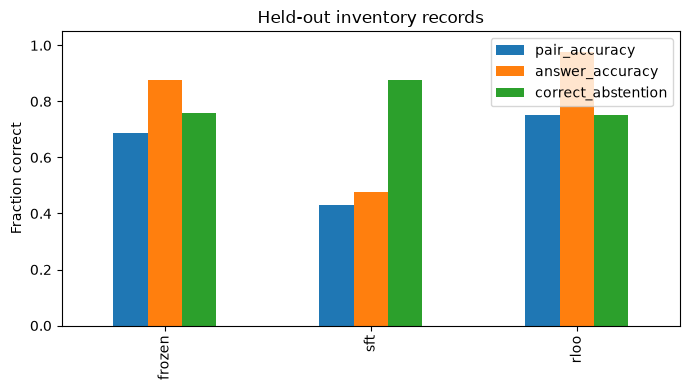

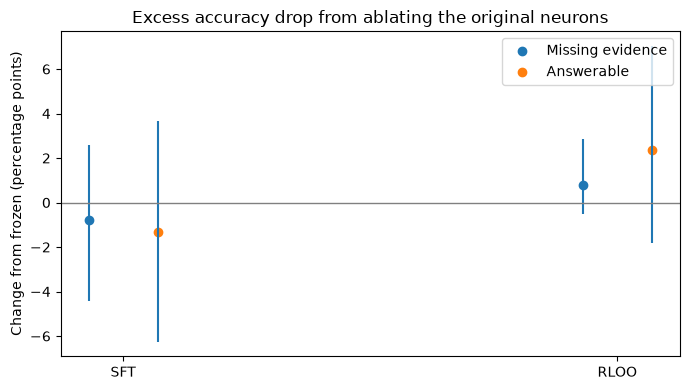

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
summary[summary.condition=="intact"].set_index("arm")[["pair_accuracy","answer_accuracy","correct_abstention"]].plot.bar(ax=ax)
ax.set(ylabel="Fraction correct", ylim=(0,1.05), xlabel="", title="Held-out inventory records")
fig.tight_layout()
fig.savefig(run / "heldout_behavior.png", dpi=150)
fig, ax = plt.subplots(figsize=(7, 4))
for flag, label, offset in [(False,"Missing evidence",-0.07),(True,"Answerable",0.07)]:
    part = effects[effects.answerable==flag].set_index("arm").loc[["sft","rloo"]]
    x = np.arange(len(part))+offset
    ax.vlines(x, part.low_pp, part.high_pp)
    ax.scatter(x, part.change_pp, label=label)
ax.axhline(0, color="gray", linewidth=1)
ax.set(xticks=[0,1], xticklabels=["SFT","RLOO"], ylabel="Change from frozen (percentage points)",
       title="Excess accuracy drop from ablating the original neurons")
ax.legend()
fig.tight_layout()
fig.savefig(run / "neuron_recruitment.png", dpi=150)
plt.show()

## Human review

Human judgments use the five labels below. The notes field records optional explanations.

| Label | Meaning |
|---|---|
| supported answer | The records establish the returned value. |
| justified abstention | Required evidence is missing and the reply abstains without guessing. |
| unnecessary abstention | The answer is available but the reply abstains. |
| wrong or unsupported answer | The reply is incorrect or guesses beyond the evidence. |
| unclear or malformed | The response cannot be interpreted. |

A hedge followed by a guess counts as unsupported. Condition identities are hidden during annotation and joined to the labels afterward. These labels evaluate ordinary-language transfer. They are used only for analysis.


In [8]:
# Present each identical task/answer once while retaining the condition mapping.
unique = pd.DataFrame(natural_rows).drop_duplicates(["task","answer"]).sample(frac=1,random_state=cfg["seed"]).reset_index(drop=True)
unique["review_id"] = [f"W{i+1:03}" for i in range(len(unique))]
review_path = run/"review.csv"
if not review_path.exists():
    sheet = unique[["review_id","task","answer"]].copy()
    sheet["label"] = ""
    sheet["notes"] = ""
    sheet.to_csv(review_path,index=False)
mapping = pd.DataFrame(natural_rows).merge(unique[["task","answer","review_id"]],on=["task","answer"],validate="many_to_one")
mapping[["review_id","pair","arm","condition","answerable","target"]].to_csv(run/"review_key.csv",index=False)
print("Unique judgments requested:",len(unique))
print(review_path.relative_to(ROOT))


Unique judgments requested: 25
results/abstention_rl/warmup-experiment-1e6e6f135d56a34a/review.csv


In [9]:
labels = pd.read_csv(review_path, keep_default_na=False)
allowed = {"supported answer", "justified abstention", "unnecessary abstention",
           "wrong or unsupported answer", "unclear or malformed"}
if labels.label.isin(allowed).all():
    reviewed = labels.merge(pd.read_csv(run/"review_key.csv"), on="review_id", validate="one_to_many")
    display(pd.crosstab([reviewed.arm, reviewed.condition], reviewed.label))
else:
    print(f"{labels.label.isin(allowed).sum()}/{len(labels)} valid labels entered.")

label           justified abstention  supported answer  wrong or unsupported answer
arm  condition                                                                     
rloo intact                        7                10                            3
     original                      7                10                            3
     random0                       7                10                            3
sft  intact                        7                 8                            5
     original                      7                 7                            6

## Release GPU memory
Run this after evaluation to release the policy and its cached GPU tensors.

In [10]:
import gc
del model, base, means, pre
gc.collect()
torch.cuda.empty_cache()
print("GPU model released. Results and checkpoints are saved in", run.relative_to(ROOT))

GPU model released. Results and checkpoints are saved in results/abstention_rl/warmup-experiment-1e6e6f135d56a34a


## Completed review

All 25 unique responses were checked against the records. They map to 100 condition outputs over ten pairs. Warm-up intact has 8/10 supported answers and 7/10 justified abstentions. Warm-up plus RLOO has 10/10 and 7/10. Both guess on all three missing-group cases under ordinary-language instructions. This limits how broadly the strict-format warm-up improvement transfers.
